# 여기서 카페 차리면 버틸까? — 서울 상권 데이터로 보는 창업 생존 지도

**지역특화 프로젝트 · ① 데이터 분석·AI 모델링형 + ② AI 서비스 구현형**

## 1. 문제 정의

서울에는 상권이 1,600개가 넘고, 같은 업종이라도 어느 상권에 차리느냐에 따라 결과가 크게 갈립니다.
그런데 막상 창업을 고민하는 사람은 "장사가 잘되는 곳"과 "오래 버티는 곳"을 구분해서 볼 수 있는 자료가 거의 없습니다.

이 프로젝트는 서울시가 공개한 상권 데이터로 아래 네 가지 질문에 답합니다.

| # | 질문 | 방법 |
|---|---|---|
| Q1 | 어떤 업종이 많이 벌고, 어떤 업종이 많이 망하는가? | 업종별 매출·폐업률 비교 |
| Q2 | 같은 업종(카페)이라도 상권에 따라 얼마나 다른가? | 점포당 매출 × 폐업률 사분면 분석 |
| Q3 | 서울 상권은 어떤 '성격'으로 나뉘는가? | 손님 구성(시간대·요일·성별·연령)으로 **K-Means 군집화** |
| Q4 | 다음 분기 점포당 매출을 예측할 수 있는가? | **Gradient Boosting 회귀**로 예측, 단순 기준선과 비교 |

마지막으로 분석 결과를 묶어 **상권×업종별 '창업 생존 점수'** 를 만들고, ② 웹서비스(창업 시뮬레이터)에서 쓸 데이터로 내보냅니다.

## 결과물 바로 보기

| 결과물 | 형태 | 보는 방법 |
|---|---|---|
| ① 데이터 분석·AI 모델링 | 이 노트북 | 아래로 스크롤 |
| ② AI 서비스: **서울 창업 생존 지도** | 웹페이지 | 👉 **[웹서비스 열기](https://fafa0215.github.io/seoul-startup-survival-map/)** (설치 없이 브라우저에서 바로 실행) |

웹서비스에서는 업종을 고르면 서울 1,577개 상권의 창업 생존 점수가 지도에 표시되고, 상권을 누르면 이 노트북의 AI 모델이 예측한 2026년 1분기 예상 매출·폐업률·손님 특징을 볼 수 있습니다. 사용법은 맨 아래 **10장**에 있습니다.

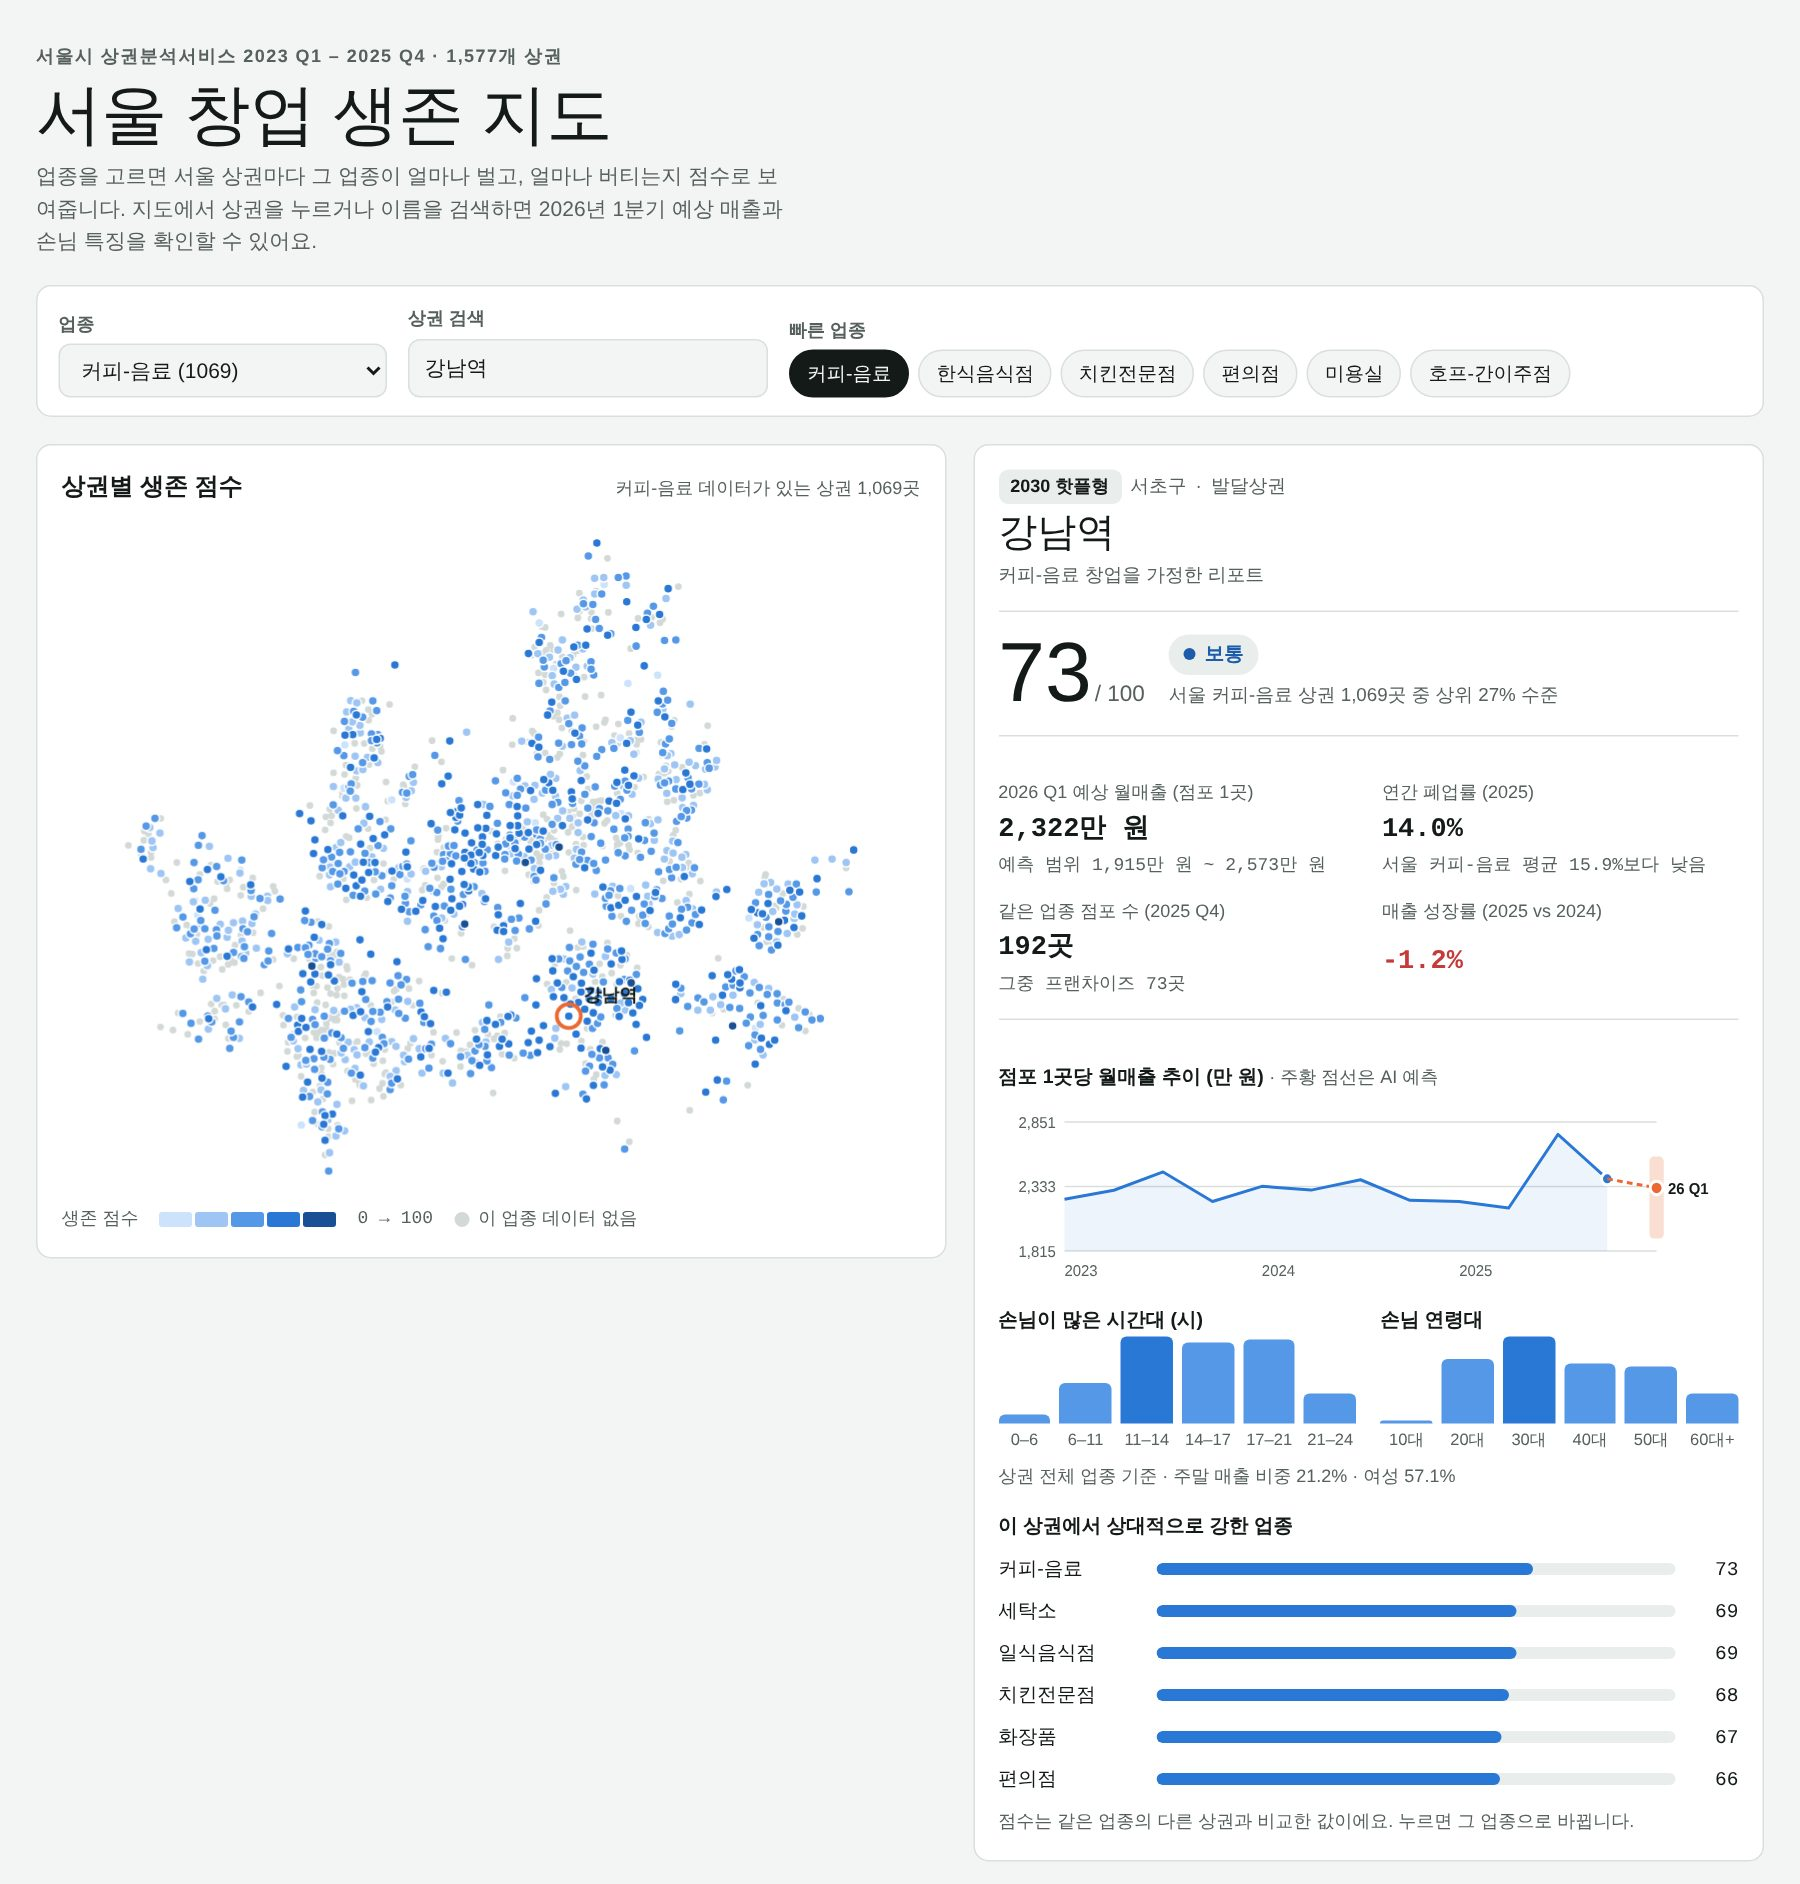

In [ ]:
# ② 웹서비스 첫 화면 (저장된 실행 결과 이미지)
from IPython.display import Image, display
try:
    display(Image('web_main.jpg'))
except (FileNotFoundError, ValueError):
    print('web_main.jpg 파일이 없으면 위 링크에서 웹서비스를 직접 확인하세요.')

## 2. 사용한 데이터와 출처

모두 [서울 열린데이터광장](https://data.seoul.go.kr)에서 무료로 내려받은 파일 데이터입니다(공공누리 1유형).

| 데이터 | 내용 | 기간 | 링크 |
|---|---|---|---|
| 서울시 상권분석서비스(추정매출-상권) | 상권×업종×분기별 추정 매출액·건수, 요일·시간대·성별·연령대별 매출 | 2023 Q1 ~ 2025 Q4 | [OA-15572](https://data.seoul.go.kr/dataList/OA-15572/S/1/datasetView.do) |
| 서울시 상권분석서비스(점포-상권) | 상권×업종×분기별 점포 수, 개업·폐업 점포 수와 비율, 프랜차이즈 점포 수 | 2023 Q1 ~ 2025 Q4 | [OA-15577](https://data.seoul.go.kr/dataList/OA-15577/S/1/datasetView.do) |
| 서울시 상권분석서비스(영역-상권) | 상권 이름·유형·자치구·행정동·중심 좌표 | - | [OA-15560](https://data.seoul.go.kr/dataList/OA-15560/S/1/datasetView.do) |

> **실행 방법**: 위 페이지에서 받은 zip 파일 7개(추정매출 3개, 점포 3개, 영역 1개)를 압축을 풀지 않고 이 노트북 옆의 `data/` 폴더에 넣은 뒤 위에서부터 실행합니다.
> 필요한 패키지: `pandas numpy matplotlib scikit-learn pyshp pyproj` (`pip install pyshp pyproj`)

**데이터 해석 시 주의**
- 매출은 카드 결제 데이터를 바탕으로 한 **추정치**이며, 파일의 `당월_매출_금액` 컬럼은 해당 **분기**의 매출로 집계되어 있습니다.
- 개·폐업률은 분기 기준이며, 점포가 몇 개 없는 상권은 한두 곳의 폐업만으로 비율이 크게 튑니다. 그래서 이 노트북은 비율을 평균하지 않고 **폐업 점포 수 합계 ÷ 점포 수 합계**로 다시 계산합니다.

In [1]:
import os, io, re, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
warnings.filterwarnings('ignore')

# 한글 폰트: Windows → 맑은 고딕, Mac → AppleGothic, 그 외 → Noto/나눔
_names = {f.name for f in fm.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if _f in _names:
        plt.rcParams['font.family'] = _f
        break
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#9a9893', 'axes.titleweight': 'bold'})
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 30)

# 차트 색 (색각이상 검증된 팔레트 순서)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948')
GRAY = '#c9c7c1'

DATA = 'data'
print(sorted(os.listdir(DATA)))

['서울시 상권분석서비스(영역-상권).zip', '서울시 상권분석서비스(점포-상권)_2024년.zip', '서울시 상권분석서비스(점포-상권)_2025년.zip', '서울시 상권분석서비스(추정매출-상권)_2024년.zip', '서울시 상권분석서비스(추정매출-상권)_2025년.zip', '서울시_상권분석서비스(점포-상권)_2023년.zip', '서울시_상권분석서비스(추정매출-상권)_2023년.zip']


## 3. 데이터 불러오기 · 정리

파일마다 인코딩(UTF-8 / CP949)과 컬럼명(한글 / 영문)이 조금씩 달라서, 읽을 때 통일합니다.

In [2]:
def read_csv_any(path):
    # 인코딩이 파일마다 달라서 UTF-8 → CP949 순서로 시도
    for enc in ('utf-8', 'cp949'):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(path)

def files(keyword):
    return sorted(os.path.join(DATA, f) for f in os.listdir(DATA) if keyword in f)

# ---- 추정매출 ----
SALES_COLS = {
    '기준_년분기_코드': '분기', '상권_구분_코드_명': '상권유형', '상권_코드': '상권코드', '상권_코드_명': '상권명',
    '서비스_업종_코드': '업종코드', '서비스_업종_코드_명': '업종명',
    '당월_매출_금액': '매출', '당월_매출_건수': '건수', '주중_매출_금액': '주중', '주말_매출_금액': '주말',
    '시간대_00~06_매출_금액': 't00_06', '시간대_06~11_매출_금액': 't06_11', '시간대_11~14_매출_금액': 't11_14',
    '시간대_14~17_매출_금액': 't14_17', '시간대_17~21_매출_금액': 't17_21', '시간대_21~24_매출_금액': 't21_24',
    '남성_매출_금액': '남성', '여성_매출_금액': '여성',
    '연령대_10_매출_금액': 'a10', '연령대_20_매출_금액': 'a20', '연령대_30_매출_금액': 'a30',
    '연령대_40_매출_금액': 'a40', '연령대_50_매출_금액': 'a50', '연령대_60_이상_매출_금액': 'a60',
}
sales = pd.concat([read_csv_any(f) for f in files('추정매출-상권')], ignore_index=True)
sales = sales.rename(columns=SALES_COLS)[list(SALES_COLS.values())]

# ---- 점포 (연도마다 컬럼명이 한글/영문으로 달라 위치로 이름을 붙임) ----
STORE_COLS = ['분기', '상권유형코드', '상권유형', '상권코드', '상권명', '업종코드', '업종명',
              '점포수', '유사업종점포수', '개업률', '개업점포수', '폐업률', '폐업점포수', '프랜차이즈점포수']
stores = []
for f in files('점포-상권'):
    d = read_csv_any(f)
    d.columns = STORE_COLS
    stores.append(d)
store = pd.concat(stores, ignore_index=True)

print('추정매출:', sales.shape, '| 분기:', sorted(sales['분기'].unique()))
print('점포   :', store.shape, '| 업종 수(매출/점포):', sales['업종코드'].nunique(), '/', store['업종코드'].nunique())
sales.head(3)

추정매출: (261157, 24) | 분기: [np.int64(20231), np.int64(20232), np.int64(20233), np.int64(20234), np.int64(20241), np.int64(20242), np.int64(20243), np.int64(20244), np.int64(20251), np.int64(20252), np.int64(20253), np.int64(20254)]
점포   : (919405, 14) | 업종 수(매출/점포): 63 / 100


,분기,상권유형,상권코드,상권명,업종코드,업종명,매출,건수,주중,주말,t00_06,t06_11,t11_14,t14_17,t17_21,t21_24,남성,여성,a10,a20,a30,a40,a50,a60
0,20241,골목상권,3110001,이북5도청사,CS100001,한식음식점,385150643,11743,220129223,165021420,0,3760615,147548112,84453676,144941846,4446394,201770831,121416122,375991,9236194,24711655,57828917,91638059,139396136
1,20241,골목상권,3110001,이북5도청사,CS100009,호프-간이주점,11026440,214,6576206,4450234,1760462,0,88580,755956,3582143,4839299,7260408,1488313,0,0,0,1926993,2835272,3986456
2,20241,골목상권,3110001,이북5도청사,CS200001,일반교습학원,52047765,224,50535211,1512554,2276791,7928965,8844458,5047152,26437845,1512554,15635027,36412738,0,0,1512554,34183711,16351500,0


In [3]:
# ---- 상권 영역: 이름·자치구·중심좌표 (EPSG:5181 → 위경도) ----
import shapefile                     # pip install pyshp
from pyproj import Transformer       # pip install pyproj

with zipfile.ZipFile(files('영역-상권')[0]) as z:
    dbf_name = [n for n in z.namelist() if n.lower().endswith('.dbf')][0]
    dbf = io.BytesIO(z.read(dbf_name))
r = shapefile.Reader(dbf=dbf, encoding='utf-8')
area = pd.DataFrame(r.records(), columns=[f[0] for f in r.fields[1:]])
area = area.rename(columns={'TRDAR_CD': '상권코드', 'XCNTS_VALU': 'x', 'YDNTS_VALU': 'y',
                            'SIGNGU_CD_': '자치구', 'ADSTRD_CD_': '행정동', 'RELM_AR': '면적'})
area['상권코드'] = area['상권코드'].astype(int)
tf = Transformer.from_crs('EPSG:5181', 'EPSG:4326', always_xy=True)
area['lon'], area['lat'] = tf.transform(area['x'].values, area['y'].values)
area = area[['상권코드', '자치구', '행정동', '면적', 'lon', 'lat']]
print(area.shape)
area.head(3)

(1650, 6)


,상권코드,자치구,행정동,면적,lon,lat
0,3110008,종로구,청운효자동,149264,126.97,37.58
1,3001494,종로구,종로1·2·3·4가동,653127,127.00,37.57
2,3130021,종로구,숭인2동,9800,127.02,37.57


In [4]:
# ---- 매출 + 점포 결합 ----
df = sales.merge(store[['분기', '상권코드', '업종코드', '점포수', '유사업종점포수', '개업점포수', '폐업점포수', '프랜차이즈점포수']],
                 on=['분기', '상권코드', '업종코드'], how='left')
df = df.merge(area, on='상권코드', how='left')

df['연도'] = df['분기'] // 10
df['분기번호'] = df['분기'] % 10
df['분기라벨'] = df['연도'].astype(str) + ' Q' + df['분기번호'].astype(str)
# 점포당 매출: 같은 업종(유사업종 포함) 점포 1곳이 한 분기에 올린 평균 매출
df['점포당매출'] = df['매출'] / df['유사업종점포수'].replace(0, np.nan)

print('결합 후:', df.shape)
print('점포 정보가 없는 행 비율 :', df['점포수'].isna().mean().round(4))
print('좌표가 없는 행 비율      :', df['lat'].isna().mean().round(4))
print('상권 수:', df['상권코드'].nunique(), '| 업종 수:', df['업종명'].nunique())

결합 후: (261157, 38)
점포 정보가 없는 행 비율 : 0.0
좌표가 없는 행 비율      : 0.0
상권 수: 1587 | 업종 수: 63


## 4. 탐색적 분석

### 4-1. 서울 전체 매출은 어떻게 움직이나

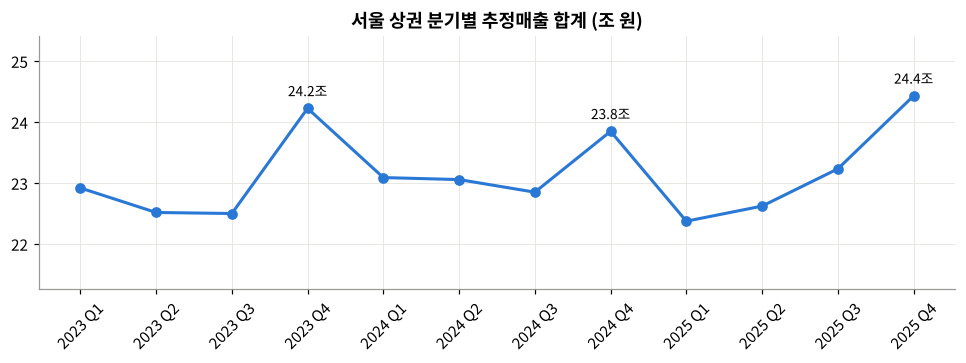

분기 평균: 23.14 조 원 / 4분기 평균 대비 나머지 분기: 0.06


In [5]:
q = df.groupby('분기라벨', sort=False)['매출'].sum().div(1e12)
q = q.reindex(sorted(q.index))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(q.index, q.values, color=BLUE, lw=2, marker='o', ms=6)
for i, (k, v) in enumerate(q.items()):
    if k.endswith('Q4'):
        ax.annotate(f'{v:.1f}조', (i, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
ax.set_title('서울 상권 분기별 추정매출 합계 (조 원)')
ax.set_ylim(q.min() * 0.95, q.max() * 1.04)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
print('분기 평균:', round(q.mean(), 2), '조 원 / 4분기 평균 대비 나머지 분기:',
      round(q[[i for i in q.index if i.endswith('Q4')]].mean() / q[[i for i in q.index if not i.endswith('Q4')]].mean() - 1, 3))

서울 상권 전체 매출은 분기당 약 23조 원 수준으로 3년간 거의 평평하고, **매년 4분기(연말)에 가장 높아지는 계절성**이 뚜렷합니다.
그래서 뒤의 예측 모델에는 '작년 같은 분기 매출'을 특징으로 넣습니다.

### 4-2. 업종별: 많이 버는 업종 vs 많이 망하는 업종 (Q1)

점포 수가 많은 상권-업종 조합에 가중치가 실리도록, 최근 1년(2025년) 기준으로 **합계끼리 나눠** 계산합니다.
- 점포당 월매출 = (연간 매출 합 ÷ 4) ÷ 평균 점포 수 ÷ 3
- 연간 폐업률 = 연간 폐업 점포 수 합 ÷ 평균 점포 수

In [6]:
y25 = df[df['연도'] == 2025]
ind = y25.groupby('업종명').agg(매출=('매출', 'sum'), 점포=('유사업종점포수', 'sum'),
                              폐업=('폐업점포수', 'sum'), 개업=('개업점포수', 'sum'), 프랜차이즈=('프랜차이즈점포수', 'sum'))
ind['평균점포수'] = ind['점포'] / 4
ind['점포당월매출(만원)'] = ind['매출'] / ind['점포'] / 3 / 1e4
ind['연간폐업률(%)'] = ind['폐업'] / ind['평균점포수'] * 100
ind['연간개업률(%)'] = ind['개업'] / ind['평균점포수'] * 100
ind['프랜차이즈비율(%)'] = ind['프랜차이즈'] / ind['점포'] * 100
ind = ind[ind['평균점포수'] >= 300]          # 점포가 너무 적은 업종은 제외
print('분석 대상 업종 수:', len(ind))
ind[['평균점포수', '점포당월매출(만원)', '연간폐업률(%)', '연간개업률(%)', '프랜차이즈비율(%)']].sort_values('연간폐업률(%)', ascending=False).head(10).round(1)

분석 대상 업종 수: 59


,평균점포수,점포당월매출(만원),연간폐업률(%),연간개업률(%),프랜차이즈비율(%)
업종명,,,,,
전자상거래업,"2,981.50",395.30,16.70,1.00,0.00
호프-간이주점,"13,885.20","1,758.30",16.50,9.20,10.90
커피-음료,"21,235.00","1,082.40",15.90,13.10,25.80
분식전문점,"8,506.80","1,071.80",15.50,13.20,23.70
중식음식점,"4,409.00","1,883.40",14.90,13.00,14.00
패스트푸드점,"3,802.80","1,385.60",14.90,12.40,54.00
한식음식점,"50,175.20","2,501.20",14.80,14.40,12.00
치킨전문점,"3,152.80",936.60,14.50,13.20,63.00
양식음식점,"6,299.80","1,846.60",14.30,11.70,9.90


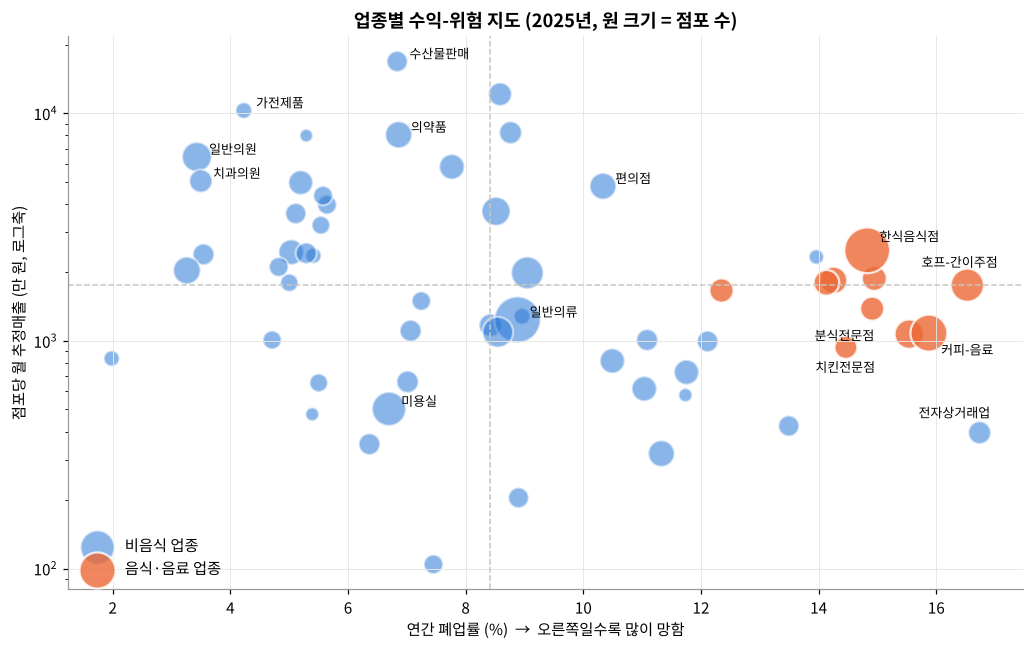

In [7]:
FOOD = {'커피-음료', '한식음식점', '치킨전문점', '분식전문점', '호프-간이주점', '패스트푸드점', '제과점',
        '양식음식점', '일식음식점', '중식음식점'}
fig, ax = plt.subplots(figsize=(9.5, 6))
is_food = ind.index.isin(FOOD)
ax.scatter(ind.loc[~is_food, '연간폐업률(%)'], ind.loc[~is_food, '점포당월매출(만원)'],
           s=np.sqrt(ind.loc[~is_food, '평균점포수']) * 4, color=BLUE, alpha=.55, edgecolor='white', lw=1.5, label='비음식 업종')
ax.scatter(ind.loc[is_food, '연간폐업률(%)'], ind.loc[is_food, '점포당월매출(만원)'],
           s=np.sqrt(ind.loc[is_food, '평균점포수']) * 4, color=ORANGE, alpha=.8, edgecolor='white', lw=1.5, label='음식·음료 업종')
label = {'커피-음료': (8, -14), '한식음식점': (8, 6), '호프-간이주점': (-30, 12), '치킨전문점': (-20, -16), '분식전문점': (-62, -4),
         '일반의원': (8, 2), '치과의원': (8, 2), '의약품': (8, 2), '가전제품': (8, 2), '미용실': (8, 2),
         '일반의류': (8, 2), '편의점': (8, 2), '전자상거래업': (-40, 10), '수산물판매': (8, 2)}
for n, off in label.items():
    if n in ind.index:
        r_ = ind.loc[n]
        ax.annotate(n, (r_['연간폐업률(%)'], r_['점포당월매출(만원)']), xytext=off, textcoords='offset points', fontsize=8.5)
ax.axvline(ind['연간폐업률(%)'].median(), color=GRAY, ls='--', lw=1)
ax.axhline(ind['점포당월매출(만원)'].median(), color=GRAY, ls='--', lw=1)
ax.set_yscale('log')
ax.set_xlabel('연간 폐업률 (%)  →  오른쪽일수록 많이 망함')
ax.set_ylabel('점포당 월 추정매출 (만 원, 로그축)')
ax.set_title('업종별 수익-위험 지도 (2025년, 원 크기 = 점포 수)')
ax.legend(loc='lower left', frameon=False)
plt.tight_layout(); plt.show()

In [8]:
food = ind.loc[ind.index.isin(FOOD), ['평균점포수', '점포당월매출(만원)', '연간폐업률(%)', '연간개업률(%)', '프랜차이즈비율(%)']]
food.sort_values('연간폐업률(%)', ascending=False).round(1)

,평균점포수,점포당월매출(만원),연간폐업률(%),연간개업률(%),프랜차이즈비율(%)
업종명,,,,,
호프-간이주점,"13,885.20","1,758.30",16.50,9.20,10.90
커피-음료,"21,235.00","1,082.40",15.90,13.10,25.80
분식전문점,"8,506.80","1,071.80",15.50,13.20,23.70
중식음식점,"4,409.00","1,883.40",14.90,13.00,14.00
패스트푸드점,"3,802.80","1,385.60",14.90,12.40,54.00
한식음식점,"50,175.20","2,501.20",14.80,14.40,12.00
치킨전문점,"3,152.80",936.60,14.50,13.20,63.00
양식음식점,"6,299.80","1,846.60",14.30,11.70,9.90
일식음식점,"4,953.20","1,801.40",14.10,5.20,15.80


**Q1 답**: 업종 간 차이가 매우 큽니다. 일반의원·약국(의약품)·가전제품처럼 진입장벽이 있는 업종은 폐업률이 낮고 점포당 매출이 높은 반면(왼쪽 위),
**커피-음료·패스트푸드·치킨·분식 같은 음식·음료 업종은 폐업률이 가장 높은 그룹**에 몰려 있습니다.
특히 카페는 점포 수가 한식 다음으로 많으면서 폐업률도 최상위권이라, '쉽게 열고 쉽게 닫는' 대표 업종입니다. 이 노트북에서 카페를 주인공으로 삼은 이유입니다.

### 4-3. 상권 유형별 차이

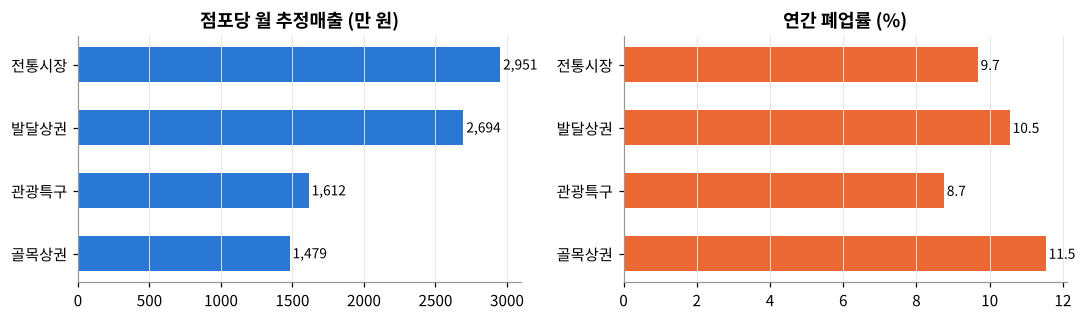

,상권수,점포당월매출(만원),연간폐업률(%)
상권유형,,,
골목상권,1039,"1,479.40",11.50
관광특구,6,"1,612.30",8.70
발달상권,249,"2,694.50",10.50
전통시장,283,"2,951.30",9.70


In [9]:
t = y25.groupby('상권유형').agg(매출=('매출', 'sum'), 점포=('유사업종점포수', 'sum'), 폐업=('폐업점포수', 'sum'), 상권수=('상권코드', 'nunique'))
t['점포당월매출(만원)'] = t['매출'] / t['점포'] / 3 / 1e4
t['연간폐업률(%)'] = t['폐업'] / (t['점포'] / 4) * 100
t = t.sort_values('점포당월매출(만원)')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].barh(t.index, t['점포당월매출(만원)'], color=BLUE, height=.55)
axes[0].set_title('점포당 월 추정매출 (만 원)')
axes[1].barh(t.index, t['연간폐업률(%)'], color=ORANGE, height=.55)
axes[1].set_title('연간 폐업률 (%)')
for ax, col in zip(axes, ['점포당월매출(만원)', '연간폐업률(%)']):
    for i, v in enumerate(t[col]):
        ax.text(v, i, f' {v:,.0f}' if col.startswith('점포') else f' {v:.1f}', va='center', fontsize=9)
    ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
t[['상권수', '점포당월매출(만원)', '연간폐업률(%)']].round(1)

서울 상권의 3분의 2를 차지하는 **골목상권은 점포당 매출이 가장 낮고 폐업률은 가장 높습니다.**
발달상권과 전통시장은 점포당 매출이 골목상권의 2배 가까이 되고 폐업률도 낮습니다. 관광특구는 6곳뿐이라 일반화하기 어렵습니다.
(단, 임대료·권리금 같은 비용 정보가 이 데이터에는 없어서 '매출이 높다 = 남는 게 많다'는 아닙니다.)

### 4-4. 카페 집중 분석: 같은 업종, 상권마다 얼마나 다를까 (Q2)

카페가 평균 10곳 이상인 상권만 남기고(점포가 몇 개 안 되면 한 곳만 닫아도 폐업률이 크게 튀기 때문), 2025년 1년치를 기준으로 상권별 **점포당 월매출**과 **연간 폐업률**을 비교합니다.

In [10]:
def market_year(data, industry, min_stores=10):
    d = data[(data['업종명'] == industry) & (data['연도'] == 2025)]
    g = d.groupby(['상권코드', '상권명', '상권유형', '자치구']).agg(
        매출=('매출', 'sum'), 점포=('유사업종점포수', 'sum'), 폐업=('폐업점포수', 'sum'), 분기수=('분기', 'nunique')).reset_index()
    g = g[g['분기수'] == 4]
    g['평균점포수'] = g['점포'] / 4
    g['점포당월매출(만원)'] = g['매출'] / g['점포'] / 3 / 1e4
    g['연간폐업률(%)'] = g['폐업'] / g['평균점포수'] * 100
    return g[g['평균점포수'] >= min_stores]

cafe = market_year(df, '커피-음료', min_stores=10)
mx, my = cafe['연간폐업률(%)'].median(), cafe['점포당월매출(만원)'].median()
def quadrant(r_):
    hi_sales, lo_close = r_['점포당월매출(만원)'] >= my, r_['연간폐업률(%)'] <= mx
    return {(True, True): '① 잘 벌고 잘 버팀', (True, False): '② 잘 벌지만 경쟁 치열',
            (False, True): '③ 조용히 버팀', (False, False): '④ 벌이도 적고 많이 닫음'}[(hi_sales, lo_close)]
cafe['유형'] = cafe.apply(quadrant, axis=1)
print('분석 상권 수:', len(cafe), '| 점포당 월매출 중앙값:', round(my), '만 원 | 폐업률 중앙값:', round(mx, 1), '%')
print('같은 카페라도 상권 상위 10% / 하위 10% 점포당 매출 차이:',
      round(cafe['점포당월매출(만원)'].quantile(.9) / cafe['점포당월매출(만원)'].quantile(.1), 1), '배')
cafe['유형'].value_counts()

분석 상권 수: 563 | 점포당 월매출 중앙값: 619 만 원 | 폐업률 중앙값: 15.6 %
같은 카페라도 상권 상위 10% / 하위 10% 점포당 매출 차이: 15.1 배


유형
① 잘 벌고 잘 버팀       163
④ 벌이도 적고 많이 닫음    162
② 잘 벌지만 경쟁 치열     119
③ 조용히 버팀          119
Name: count, dtype: int64

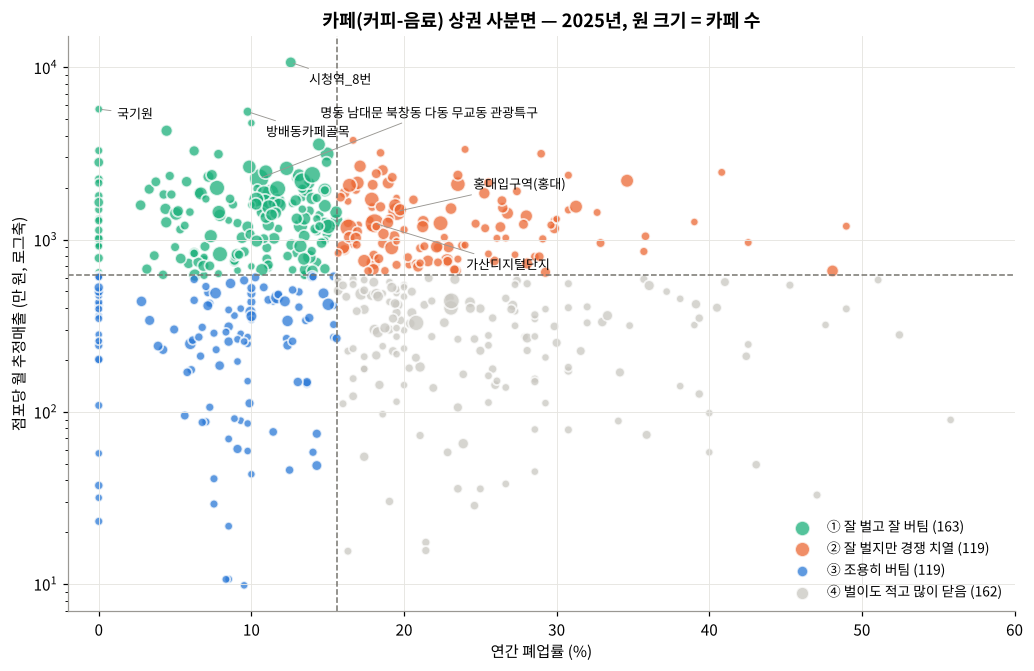

In [11]:
colors = {'① 잘 벌고 잘 버팀': AQUA, '② 잘 벌지만 경쟁 치열': ORANGE, '③ 조용히 버팀': BLUE, '④ 벌이도 적고 많이 닫음': GRAY}
fig, ax = plt.subplots(figsize=(9.5, 6.2))
for k, c in colors.items():
    d = cafe[cafe['유형'] == k]
    ax.scatter(d['연간폐업률(%)'], d['점포당월매출(만원)'], s=np.sqrt(d['평균점포수']) * 9,
               color=c, alpha=.75, edgecolor='white', lw=1.2, label=f'{k} ({len(d)})')
ax.axvline(mx, color='#77756f', ls='--', lw=1); ax.axhline(my, color='#77756f', ls='--', lw=1)
show = pd.concat([cafe.nlargest(3, '평균점포수'), cafe[cafe['유형'] == '① 잘 벌고 잘 버팀'].nlargest(3, '점포당월매출(만원)')]).drop_duplicates('상권코드')
offs = [(40, 40), (60, -30), (50, 15), (12, -14), (12, -6), (12, -16)]
for k_, (_, r_) in enumerate(show.iterrows()):
    ax.annotate(r_['상권명'], (r_['연간폐업률(%)'], r_['점포당월매출(만원)']), xytext=offs[k_ % len(offs)],
                textcoords='offset points', fontsize=8.5, arrowprops=dict(arrowstyle='-', color='#9a9893', lw=.6))
ax.set_yscale('log')
ax.set_xlim(-2, min(60, cafe['연간폐업률(%)'].max() + 2))
ax.set_xlabel('연간 폐업률 (%)'); ax.set_ylabel('점포당 월 추정매출 (만 원, 로그축)')
ax.set_title('카페(커피-음료) 상권 사분면 — 2025년, 원 크기 = 카페 수')
ax.legend(frameon=False, fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

In [12]:
print('① 잘 벌고 잘 버티는 카페 상권 TOP 10')
(cafe[cafe['유형'] == '① 잘 벌고 잘 버팀']
 .sort_values('점포당월매출(만원)', ascending=False)
 [['상권명', '자치구', '상권유형', '평균점포수', '점포당월매출(만원)', '연간폐업률(%)']].head(10).round(1))

① 잘 벌고 잘 버티는 카페 상권 TOP 10


,상권명,자치구,상권유형,평균점포수,점포당월매출(만원),연간폐업률(%)
743,시청역_8번,중구,발달상권,39.80,"10,670.10",12.60
617,국기원,강남구,골목상권,11.00,"5,711.80",0.00
880,방배동카페골목,서초구,발달상권,20.50,"5,522.70",9.80
132,광나루역 1번,광진구,골목상권,10.00,"4,747.70",10.00
5,강남 마이스 관광특구,강남구,관광특구,45.00,"4,281.60",4.40
939,삼성역,강남구,발달상권,76.20,"3,564.10",14.40
758,장충동족발거리(남소영길),중구,발달상권,12.80,"3,281.60",0.00
861,당산역,영등포구,발달상권,32.00,"3,268.60",6.20
750,명동(명동거리),중구,발달상권,100.20,"3,139.90",15.00
941,수서역,강남구,발달상권,25.50,"3,129.40",7.80


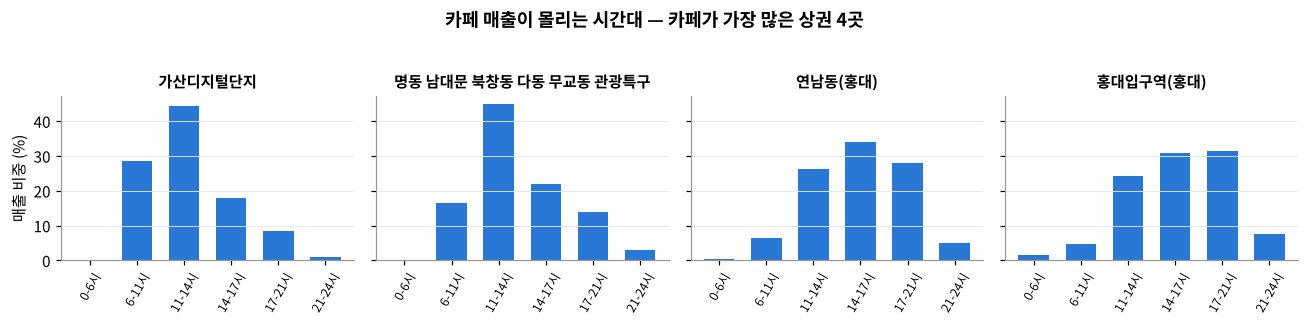

In [13]:
# 카페가 가장 많은 상권 4곳의 '손님이 언제 오는가' 비교
TIME = ['t00_06', 't06_11', 't11_14', 't14_17', 't17_21', 't21_24']
TIME_LB = ['0-6시', '6-11시', '11-14시', '14-17시', '17-21시', '21-24시']
top4 = cafe.nlargest(4, '평균점포수')['상권코드']
d = df[(df['업종명'] == '커피-음료') & (df['연도'] == 2025) & (df['상권코드'].isin(top4))]
prof = d.groupby('상권명')[TIME].sum()
prof = prof.div(prof.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, (name, row) in zip(axes, prof.iterrows()):
    ax.bar(TIME_LB, row.values, color=BLUE, width=.65)
    ax.set_title(name, fontsize=10); ax.tick_params(axis='x', rotation=60, labelsize=8); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('매출 비중 (%)')
fig.suptitle('카페 매출이 몰리는 시간대 — 카페가 가장 많은 상권 4곳', fontweight='bold', y=1.04)
plt.tight_layout(); plt.show()

**Q2 답**: 같은 카페라도 상권에 따라 점포당 매출이 수 배 차이 나고, 매출이 높은 상권이 꼭 오래 버티는 상권은 아닙니다.
점포가 몰린 대형 상권은 대체로 '② 잘 벌지만 경쟁 치열' 쪽에 있고, 손님이 오는 시간대도 상권마다 달라(오피스 상권은 점심, 대학가는 오후·저녁)
**'어디에 차리느냐'가 '무엇을 차리느냐' 만큼 중요하다**는 것을 보여줍니다.

## 5. AI ① 상권 성격 군집화 (Q3)

상권마다 **손님 구성**이 다릅니다. 상권 전체 매출을 시간대(6) · 주말 비중(1) · 여성 비중(1) · 연령대(6) 비율로 바꿔
14차원 '손님 프로필'을 만들고, K-Means로 비슷한 상권끼리 묶습니다.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

AGE = ['a10', 'a20', 'a30', 'a40', 'a50', 'a60']
AGE_LB = ['10대', '20대', '30대', '40대', '50대', '60대+']
mk = y25.groupby(['상권코드', '상권명', '상권유형', '자치구', 'lon', 'lat'])[['매출', '주말', '여성', '남성'] + TIME + AGE].sum().reset_index()
mk = mk[mk['매출'] > 0]
feat = pd.DataFrame({'상권코드': mk['상권코드']})
for c in TIME: feat[c] = mk[c] / mk[TIME].sum(axis=1)
feat['주말비중'] = mk['주말'] / mk['매출']
feat['여성비중'] = mk['여성'] / (mk['여성'] + mk['남성'])
for c in AGE: feat[c] = mk[c] / mk[AGE].sum(axis=1)
feat = feat.fillna(0)
X = StandardScaler().fit_transform(feat.drop(columns='상권코드'))

scores = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in range(3, 9)}
print('실루엣 점수:', {k: round(v, 3) for k, v in scores.items()})

실루엣 점수: {3: 0.135, 4: 0.152, 5: 0.144, 6: 0.143, 7: 0.139, 8: 0.144}


실루엣 점수는 k = 4가 가장 높지만 k = 5와 거의 차이가 없습니다(손님 구성은 연속적으로 변해서 점수가 전체적으로 낮은 편).
특징이 뚜렷한 네 무리 + 그 외 '평범한' 무리로 나뉘어 해석이 쉬운 **k = 5**를 사용합니다.

In [15]:
K = 5
km = KMeans(K, n_init=20, random_state=0).fit(X)
feat['군집'] = km.labels_
mk = mk.merge(feat, on='상권코드', suffixes=('', '_비율'))

cols = TIME + ['주말비중', '여성비중'] + AGE
center = feat.groupby('군집')[cols].mean()
overall = feat[cols].mean()
rel = (center - overall) / feat[cols].std()          # 서울 평균 대비 얼마나 튀는지 (표준편차 단위)
print((center * 100).round(1).rename(columns=dict(zip(TIME + AGE, TIME_LB + AGE_LB))))

    0-6시  6-11시  11-14시  14-17시  17-21시  21-24시  주말비중  여성비중  10대   20대   30대  \
군집                                                                             
0   1.20  15.40   29.40   28.50   22.00    3.50 21.90 50.60 0.20  4.50 11.90   
1   8.50   5.80   16.20   12.90   35.60   21.00 28.70 38.60 0.50 13.90 26.10   
2   3.10   5.80   26.20   24.20   31.30    9.30 29.40 53.90 1.80 28.10 26.20   
3   1.10   9.80   25.20   28.60   29.10    6.30 18.40 53.40 0.30  4.00 12.60   
4   2.60   8.70   26.90   19.70   32.70    9.40 25.00 43.50 0.30  7.60 18.50   

     40대   50대  60대+  
군집                    
0  17.50 25.30 40.70  
1  20.70 20.80 18.10  
2  16.40 16.90 10.60  
3  46.20 22.70 14.20  
4  21.70 25.30 26.60  


In [16]:
# 군집 중심을 보고 이름 붙이기: 가장 튀는 특징을 가진 군집부터 하나씩 이름을 배정
rules = [('심야·유흥형', lambda r_: r_['t00_06'] + r_['t21_24']),
         ('2030 핫플형', lambda r_: r_['a20'] + r_['a10']),
         ('40대 학원가·아파트형', lambda r_: r_['a40']),
         ('5060 시장·생활형', lambda r_: r_['a60'] + r_['a50'])]
names, left = {}, set(range(K))
for nm, f in rules:
    c = max(left, key=lambda c: f(rel.loc[c]))
    names[c] = nm; left.remove(c)
for c in left: names[c] = '복합 생활형'
mk['상권성격'] = mk['군집'].map(names)
summary = mk.groupby('상권성격').agg(상권수=('상권코드', 'size'),
                                  대표상권=('상권명', lambda s: ', '.join(s.loc[mk.loc[s.index, '매출'].nlargest(4).index])))
summary

,상권수,대표상권
상권성격,,
2030 핫플형,119,"강남역, 잠실 관광특구, 잠실역, 홍대입구역(홍대)"
40대 학원가·아파트형,155,"은마아파트, 장한평역(장한평), 고덕역, 목동신시가지"
5060 시장·생활형,413,"용산전자상가(용산역), 명동 남대문 북창동 다동 무교동 관광특구, 청량리청과물시장,..."
복합 생활형,653,"노량진역(노량진), 가산디지털단지, 종로3가역, 종로·청계 관광특구"
심야·유흥형,237,"가락시장, 영등포역(영등포), 수유역, 종각역"


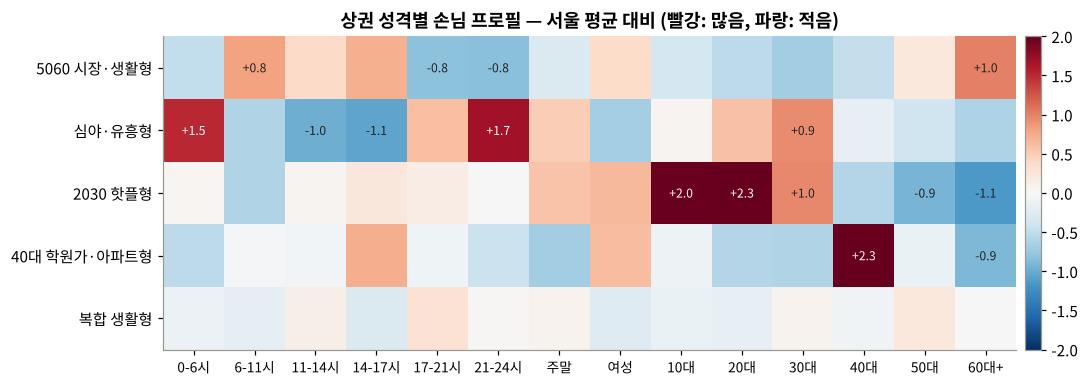

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.6))
heat = rel.rename(index=names, columns=dict(zip(TIME + AGE + ['주말비중', '여성비중'], TIME_LB + AGE_LB + ['주말', '여성'])))
im = ax.imshow(heat.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=0, fontsize=9)
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if abs(v) >= 0.8: ax.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 1.4 else '#222')
ax.grid(False)
ax.set_title('상권 성격별 손님 프로필 — 서울 평균 대비 (빨강: 많음, 파랑: 적음)')
plt.colorbar(im, ax=ax, fraction=.02, pad=.01)
plt.tight_layout(); plt.show()

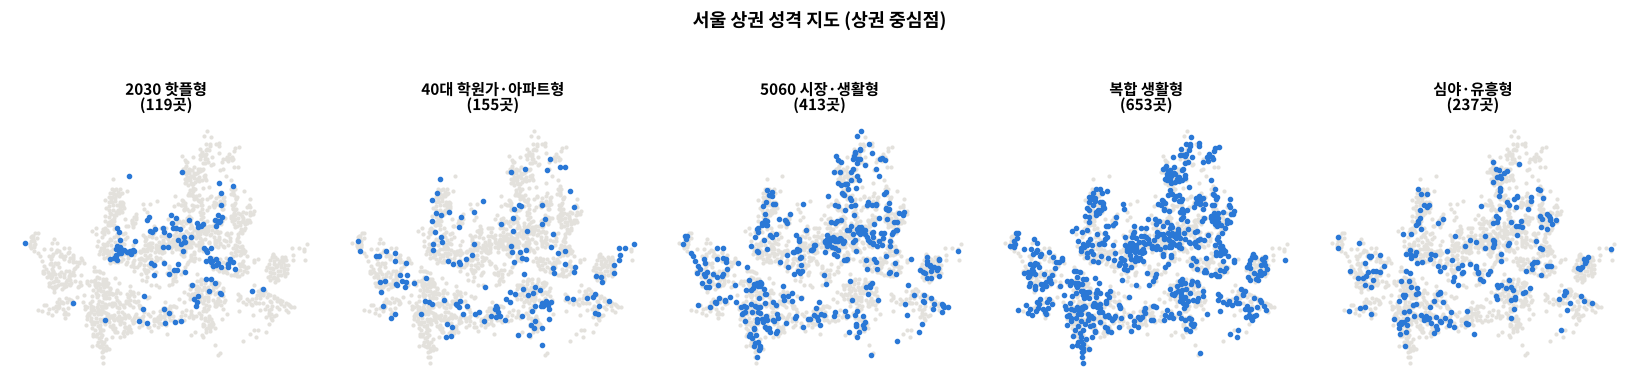

In [18]:
# 지도: 성격별로 한 장씩 (전체 상권은 회색 배경)
order = list(summary.index)
fig, axes = plt.subplots(1, K, figsize=(15, 3.3), sharex=True, sharey=True)
for ax, n in zip(axes, order):
    ax.scatter(mk['lon'], mk['lat'], s=3, color='#e3e1dc')
    d = mk[mk['상권성격'] == n]
    ax.scatter(d['lon'], d['lat'], s=7, color=BLUE)
    ax.set_title(f'{n}\n({len(d)}곳)', fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle('서울 상권 성격 지도 (상권 중심점)', fontweight='bold', y=1.05)
plt.tight_layout(); plt.show()

**Q3 답**: 손님 구성만으로 서울 상권은 다섯 가지 성격으로 나뉩니다.
- **2030 핫플형**: 20대 매출이 서울 평균보다 훨씬 높고 저녁·주말에 강함 (강남역·홍대·잠실 등)
- **심야·유흥형**: 밤 9시~새벽 매출 비중이 높고 남성 손님 비중이 높음
- **40대 학원가·아파트형**: 40대 매출이 압도적 — 학원가·대단지 아파트 상권 (대치·목동 등)
- **5060 시장·생활형**: 오전 장사와 50~60대 비중이 높음, 전통시장·노포 상권
- **복합 생활형**: 특정 손님층이 튀지 않는 일반 동네 상권 (가장 많음)

창업할 때 **내 업종의 주 고객층과 상권 성격이 맞는지**를 보는 기준으로 쓸 수 있습니다(예: 디저트 카페 → 2030 핫플형, 아침 커피 → 5060 생활형은 피하기 등).

## 6. AI ② 다음 분기 점포당 매출 예측 (Q4)

**목표**: 어떤 상권-업종의 *이번 분기* 정보를 보고 *다음 분기* 점포당 매출을 예측합니다.

| 구분 | 내용 |
|---|---|
| 예측 대상 | 다음 분기 log(점포당 매출) |
| 입력 특징 | 이번 분기·직전 분기·작년 같은 분기의 점포당 매출, 점포 수, 프랜차이즈 비율, 개·폐업 점포 수, 손님 구성(시간대·연령·주말), 업종, 상권 유형, 상권 성격, 다음 분기가 몇 분기인지 |
| 모델 | `HistGradientBoostingRegressor` (scikit-learn) |
| 검증 | **시간 순서로 분리** — 2025 Q2까지를 학습, 2025 Q3·Q4 예측을 평가 (미래 정보가 섞이지 않게) |
| 비교 기준선 | ① "다음 분기도 이번과 같다" ② "작년 같은 분기 × 최근 1년 성장률" |

In [19]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

base = df[(df['유사업종점포수'] >= 3) & (df['매출'] > 0)].copy()
base['qidx'] = (base['연도'] - 2023) * 4 + base['분기번호'] - 1          # 0 ~ 11
base['y_log'] = np.log(base['점포당매출'])
key = ['상권코드', '업종코드']

lag = base[key + ['qidx', 'y_log']]
def shift(k, name):
    s = lag.copy(); s['qidx'] = s['qidx'] + k
    return s.rename(columns={'y_log': name})
P = base.merge(shift(1, 'lag1'), on=key + ['qidx'], how='left')       # 직전 분기
P = P.merge(shift(3, 'lag3'), on=key + ['qidx'], how='left')          # 다음 분기의 작년 같은 분기
P = P.merge(shift(4, 'lag4'), on=key + ['qidx'], how='left')          # 이번 분기의 작년 같은 분기
P = P.merge(shift(-1, 'target'), on=key + ['qidx'], how='left')       # 정답: 다음 분기

tot = P[TIME].sum(axis=1).replace(0, np.nan); agt = P[AGE].sum(axis=1).replace(0, np.nan)
for c in TIME: P[c + '_r'] = P[c] / tot
for c in AGE: P[c + '_r'] = P[c] / agt
P['주말_r'] = P['주말'] / P['매출']
P['프랜차이즈_r'] = P['프랜차이즈점포수'] / P['점포수'].replace(0, np.nan)
P['next_q'] = (P['분기번호'] % 4) + 1
P['log_store'] = np.log1p(P['유사업종점포수'])
P = P.merge(mk[['상권코드', '군집']], on='상권코드', how='left')
for c in ['업종코드', '상권유형']:
    P[c + '_cat'] = P[c].astype('category').cat.codes
P['군집'] = P['군집'].fillna(-1)

FEATS = ['y_log', 'lag1', 'lag3', 'lag4', 'log_store', '개업점포수', '폐업점포수', '프랜차이즈_r', '주말_r',
         *[c + '_r' for c in TIME], *[c + '_r' for c in AGE], 'next_q', '업종코드_cat', '상권유형_cat', '군집']
CAT = [FEATS.index(c) for c in ['업종코드_cat', '상권유형_cat', '군집', 'next_q']]

data = P.dropna(subset=['target'])
train, test = data[data['qidx'] <= 8], data[data['qidx'] >= 9]       # 정답 분기 ≤ 2025Q2 / 2025Q3·Q4
print('학습:', len(train), '행 | 평가:', len(test), '행')

model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_leaf_nodes=48,
                                      categorical_features=CAT, random_state=0)
model.fit(train[FEATS], train['target'])
pred = model.predict(test[FEATS])

학습: 191643 행 | 평가: 41774 행


In [20]:
def evaluate(name, p, y):
    m = ~np.isnan(p)
    err = np.exp(p[m]) / np.exp(y[m]) - 1
    return {'방법': name, '평가 행 수': int(m.sum()),
            'MAE (log)': np.mean(np.abs(p[m] - y[m])),
            '오차 중앙값 (%)': np.median(np.abs(err)) * 100,
            '±20% 안에 든 비율 (%)': np.mean(np.abs(err) <= .2) * 100,
            'R²': 1 - np.sum((y[m] - p[m]) ** 2) / np.sum((y[m] - y[m].mean()) ** 2)}

y = test['target'].values
naive = test['y_log'].values
seasonal = (test['lag3'] + (test['y_log'] - test['lag4'])).values         # 작년 같은 분기 × 최근 성장률
res = pd.DataFrame([evaluate('기준선① 이번 분기와 같다', naive, y),
                    evaluate('기준선② 작년 같은 분기 × 성장률', seasonal, y),
                    evaluate('Gradient Boosting (이 프로젝트)', pred, y)]).set_index('방법')
res.round(3)

,평가 행 수,MAE (log),오차 중앙값 (%),±20% 안에 든 비율 (%),R²
방법,,,,,
기준선① 이번 분기와 같다,41774,0.30,15.19,59.18,0.88
기준선② 작년 같은 분기 × 성장률,39815,0.37,18.47,52.57,0.81
Gradient Boosting (이 프로젝트),41774,0.28,14.74,60.67,0.91


In [21]:
# 공정 비교: 세 방법 모두 예측이 가능한 같은 행에서만
mask = ~np.isnan(seasonal)
pd.DataFrame([evaluate('기준선①', naive[mask], y[mask]), evaluate('기준선②', seasonal[mask], y[mask]),
              evaluate('Gradient Boosting', pred[mask], y[mask])]).set_index('방법').round(3)

,평가 행 수,MAE (log),오차 중앙값 (%),±20% 안에 든 비율 (%),R²
방법,,,,,
기준선①,39815,0.28,14.74,60.25,0.90
기준선②,39815,0.37,18.47,52.57,0.81
Gradient Boosting,39815,0.27,14.29,61.87,0.91


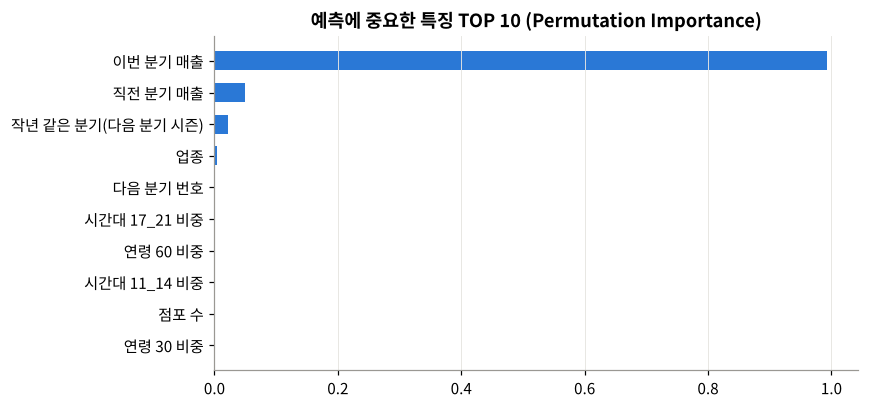

In [22]:
pi = permutation_importance(model, test[FEATS].sample(8000, random_state=0),
                            test.loc[test[FEATS].sample(8000, random_state=0).index, 'target'],
                            n_repeats=3, random_state=0)
lb = {'y_log': '이번 분기 매출', 'lag1': '직전 분기 매출', 'lag3': '작년 같은 분기(다음 분기 시즌)', 'lag4': '작년 같은 분기(이번 시즌)',
      'log_store': '점포 수', '업종코드_cat': '업종', '상권유형_cat': '상권 유형', '군집': '상권 성격', 'next_q': '다음 분기 번호',
      '개업점포수': '개업 점포 수', '폐업점포수': '폐업 점포 수', '프랜차이즈_r': '프랜차이즈 비율', '주말_r': '주말 매출 비중'}
imp = pd.Series(pi.importances_mean, index=[lb.get(f, f.replace('_r', ' 비중').replace('t', '시간대 ').replace('a', '연령 ')) for f in FEATS]).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(imp.index, imp.values, color=BLUE, height=.6)
ax.set_title('예측에 중요한 특징 TOP 10 (Permutation Importance)'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

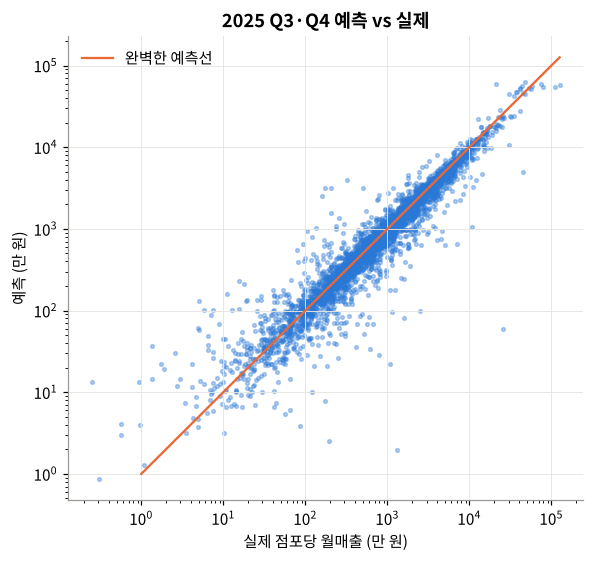

In [23]:
# 예측 vs 실제 (점포당 월매출, 만 원)
fig, ax = plt.subplots(figsize=(5.5, 5.2))
sm = np.random.RandomState(0).choice(len(y), 4000, replace=False)
a_, p_ = np.exp(y[sm]) / 3 / 1e4, np.exp(pred[sm]) / 3 / 1e4
ax.scatter(a_, p_, s=6, alpha=.35, color=BLUE)
lim = [max(1, min(a_.min(), p_.min())), max(a_.max(), p_.max())]
ax.plot(lim, lim, color=ORANGE, lw=1.5, label='완벽한 예측선')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('실제 점포당 월매출 (만 원)'); ax.set_ylabel('예측 (만 원)')
ax.set_title('2025 Q3·Q4 예측 vs 실제'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Q4 답**: 상권-업종의 매출은 관성이 커서 "이번 분기와 같다"는 단순 기준선도 꽤 잘 맞습니다.
Gradient Boosting 모델은 여기에 **작년 같은 분기 패턴(계절성)·점포 수·업종 특성**을 함께 반영해 두 기준선보다 오차를 줄였습니다
(R² 0.88 → 0.91, 오차 중앙값 약 15%). 개선 폭이 크지는 않지만, 매출이 크게 튀는 조합에서 기준선보다 덜 흔들립니다.
중요도를 보면 '이번 분기 매출'이 압도적이고, 그다음이 직전 분기 매출 · 작년 같은 시즌 매출 · 업종 순입니다. 즉 **매출에는 강한 관성이 있고, 모델은 그 위에 계절성과 업종 특성을 보정**하는 역할을 합니다.
이 모델을 2025 Q4 데이터에 적용해 **2026 Q1 점포당 매출**을 예측하고 웹서비스에 넣습니다.

> 한계: 카드 매출 기반 추정치이며 임대료·인건비 같은 비용 정보가 없어서 '매출'과 '폐업'까지만 볼 수 있습니다.

In [24]:
# 전체 데이터로 다시 학습한 뒤, 2025 Q4(qidx=11) 정보로 2026 Q1을 예측
final = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_leaf_nodes=48,
                                      categorical_features=CAT, random_state=0).fit(data[FEATS], data['target'])
latest = P[P['qidx'] == 11].copy()
latest['pred_2026Q1'] = np.exp(final.predict(latest[FEATS]))
# 테스트 구간 오차로 예측 범위(±) 추정: 오차 25~75% 구간
q25, q75 = np.quantile(pred - y, [.25, .75])
latest['pred_lo'], latest['pred_hi'] = latest['pred_2026Q1'] * np.exp(q25), latest['pred_2026Q1'] * np.exp(q75)
print('예측 범위 계수:', round(np.exp(q25), 3), '~', round(np.exp(q75), 3))
latest[['상권명', '업종명', '점포당매출', 'pred_2026Q1']].head()

예측 범위 계수: 0.825 ~ 1.108


,상권명,업종명,점포당매출,pred_2026Q1
151578,이태원 관광특구,운동/경기용품,"28,926,105.74","27,608,580.18"
151579,이태원 관광특구,커피-음료,"33,673,335.84","34,332,742.08"
151580,이태원 관광특구,의약품,"66,968,247.00","67,893,633.65"
151581,이태원 관광특구,일식음식점,"18,504,088.90","18,555,214.27"
151582,이태원 관광특구,시계및귀금속,"10,791,845.53","11,746,789.36"


## 7. 창업 생존 점수 만들기

창업자 입장에서 한 상권-업종 조합을 **0~100점**으로 요약합니다. 각 항목은 **같은 업종 안에서의 백분위**라서 업종끼리 직접 비교하지 않습니다.

| 항목 | 가중치 | 의미 |
|---|---|---|
| 예상 점포당 매출 (2026 Q1 예측) | 40% | 높을수록 좋음 |
| 최근 1년 폐업률 | 30% | 낮을수록 좋음 |
| 매출 성장률 (2025 vs 2024) | 15% | 높을수록 좋음 |
| 경쟁 증가 (개업 − 폐업, 점포 대비) | 15% | 점포가 빠르게 늘수록 감점 |

In [25]:
recent = df[df['연도'] == 2025].groupby(key).agg(매출25=('매출', 'sum'), 점포25=('유사업종점포수', 'sum'),
                                                 폐업25=('폐업점포수', 'sum'), 개업25=('개업점포수', 'sum'))
prev = df[df['연도'] == 2024].groupby(key).agg(매출24=('매출', 'sum'))
S = latest.set_index(key)[['상권명', '업종명', '상권유형', '자치구', '유사업종점포수', '프랜차이즈점포수', '점포당매출',
                          'pred_2026Q1', 'pred_lo', 'pred_hi', 'lat', 'lon']].join(recent).join(prev).reset_index()
S['평균점포수'] = S['점포25'] / 4
S['연간폐업률'] = S['폐업25'] / S['평균점포수'] * 100
S['성장률'] = (S['매출25'] / S['매출24'] - 1) * 100
S['순증가율'] = (S['개업25'] - S['폐업25']) / S['평균점포수'] * 100

pct = lambda col, asc=True: S.groupby('업종코드')[col].rank(pct=True, ascending=asc)
S['점수'] = (0.40 * pct('pred_2026Q1') + 0.30 * pct('연간폐업률', asc=False)
             + 0.15 * pct('성장률').fillna(.5) + 0.15 * pct('순증가율', asc=False)) * 100
S = S.merge(mk[['상권코드', '상권성격']], on='상권코드', how='left')
print('점수 계산된 상권-업종 조합:', len(S))

print('\n☕ 카페 창업 생존 점수 TOP 10 (카페 10곳 이상 상권)')
(S[(S['업종명'] == '커피-음료') & (S['평균점포수'] >= 10)].nlargest(10, '점수')
 [['상권명', '자치구', '상권성격', '평균점포수', 'pred_2026Q1', '연간폐업률', '성장률', '점수']]
 .assign(pred_2026Q1=lambda d: (d['pred_2026Q1'] / 3 / 1e4).round(0)).rename(columns={'pred_2026Q1': '예상 월매출(만원)'}).round(1))

점수 계산된 상권-업종 조합: 21333

☕ 카페 창업 생존 점수 TOP 10 (카페 10곳 이상 상권)


,상권명,자치구,상권성격,평균점포수,예상 월매출(만원),연간폐업률,성장률,점수
11718,장충동족발거리(남소영길),중구,복합 생활형,12.80,"3,809.00",0.00,145.20,83.40
225,강남 마이스 관광특구,강남구,2030 핫플형,45.00,"4,714.00",4.40,30.40,82.00
11909,"숙대입구역(남영역, 남영동)",용산구,2030 핫플형,15.00,"1,646.00",0.00,3.90,79.80
724,서울역 12번,용산구,복합 생활형,15.50,"2,127.00",12.90,18.00,79.70
11429,시청역_8번,중구,복합 생활형,39.80,"9,853.00",12.60,13.20,79.60
12870,안암역,성북구,5060 시장·생활형,14.20,"1,937.00",0.00,16.30,79.30
17482,잠실역,송파구,2030 핫플형,142.00,"1,901.00",7.70,3.60,78.60
11980,남영동 먹자골목,용산구,심야·유흥형,25.20,"1,587.00",0.00,19.20,78.10
17549,방이동먹자골목,송파구,심야·유흥형,26.00,"2,525.00",0.00,1.30,77.90
17205,코엑스,강남구,2030 핫플형,21.50,"2,456.00",4.70,19.10,77.30


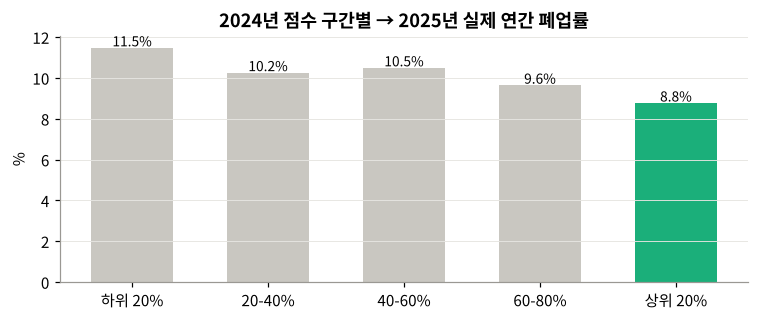

In [26]:
# 점수가 실제로 의미 있는지 확인: 2024년 기준으로 같은 방식의 점수를 매기면, 2025년 폐업률과 관계가 있을까?
chk = df[df['연도'] == 2024].groupby(key).agg(m=('매출', 'sum'), s=('유사업종점포수', 'sum'), c=('폐업점포수', 'sum'))
chk = chk[chk['s'] >= 12]
chk['per'] = chk['m'] / chk['s']; chk['close'] = chk['c'] / (chk['s'] / 4)
chk = chk.reset_index()
chk['score24'] = (0.6 * chk.groupby('업종코드')['per'].rank(pct=True) + 0.4 * chk.groupby('업종코드')['close'].rank(pct=True, ascending=False)) * 100
chk = chk.merge(S[key + ['연간폐업률']], on=key)
chk['점수구간'] = pd.qcut(chk['score24'], 5, labels=['하위 20%', '20-40%', '40-60%', '60-80%', '상위 20%'])
v = chk.groupby('점수구간', observed=True)['연간폐업률'].mean()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(v.index.astype(str), v.values, color=[GRAY] * 4 + [AQUA], width=.6)
for i, x in enumerate(v.values): ax.text(i, x, f'{x:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_title('2024년 점수 구간별 → 2025년 실제 연간 폐업률'); ax.set_ylabel('%'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

2024년 데이터만으로 매긴 점수가 높았던 곳일수록 **2025년에 실제로 덜 망했습니다**. 점수가 미래의 생존과 연결된다는 간단한 검증입니다.

## 8. 인사이트 정리

1. **업종이 1차로 운명을 가른다.** 음식·음료 업종, 특히 카페는 점포 수가 많고 폐업률이 가장 높은 그룹이다. 의원·안경점처럼 진입장벽 있는 업종은 반대.
2. **같은 업종 안에서도 상권이 2차로 운명을 가른다.** 카페 점포당 매출은 상권 상·하위 10% 사이에 몇 배 차이가 나고, 매출이 높은 상권이 곧 오래 버티는 상권은 아니다.
3. **상권에는 성격이 있다.** 손님의 시간대·연령·주말 패턴만으로 서울 상권은 다섯 가지 성격으로 나뉘고, 지도 위에서도 지역별로 뚜렷하게 모인다.
4. **다음 분기 매출은 꽤 예측 가능하다.** 최근 매출과 작년 같은 시즌 매출이 가장 강한 신호이며, 머신러닝 모델은 단순 기준선보다 오차를 줄였다.
5. **'창업 생존 점수'는 미래 폐업률과 실제로 연결된다.** 이 점수를 ② 웹서비스(창업 시뮬레이터)의 핵심 지표로 쓴다.

## 9. 웹서비스용 데이터 내보내기

In [27]:
mk_out = mk.set_index('상권코드')
markets = {}
for c, r_ in mk_out.iterrows():
    markets[int(c)] = {'n': r_['상권명'], 't': r_['상권유형'], 'g': r_['자치구'], 'c': r_['상권성격'],
                       'lat': round(float(r_['lat']), 5), 'lon': round(float(r_['lon']), 5),
                       'time': [round(float(r_[x + '_비율']) * 100, 1) for x in TIME],
                       'age': [round(float(r_[x + '_비율']) * 100, 1) for x in AGE],
                       'wk': round(float(r_['주말비중']) * 100, 1), 'fe': round(float(r_['여성비중']) * 100, 1)}

# 상권-업종별 분기 추이 (점포당 월매출, 만 원)
trend = (df[df['유사업종점포수'] >= 1].assign(v=lambda d: d['점포당매출'] / 3 / 1e4)
         .pivot_table(index=key, columns='분기', values='v'))
S2 = S.set_index(key).join(trend)
qcols = sorted(trend.columns)

def r1(x): return None if pd.isna(x) else round(float(x), 1)
rows = []
for (mc, ic), r_ in S2.iterrows():
    if int(mc) not in markets: continue
    rows.append([int(mc), ic, r1(r_['점수']), r1(r_['pred_2026Q1'] / 3 / 1e4), r1(r_['pred_lo'] / 3 / 1e4), r1(r_['pred_hi'] / 3 / 1e4),
                 int(r_['유사업종점포수']), int(r_['프랜차이즈점포수']), r1(r_['연간폐업률']), r1(r_['성장률']),
                 [r1(r_[q]) for q in qcols]])
industries = df.drop_duplicates('업종코드').set_index('업종코드')['업종명'].to_dict()
ind_stats = {k: {'close': r1(v['연간폐업률(%)']), 'sales': r1(v['점포당월매출(만원)'])} for k, v in ind.iterrows()}
out = {'quarters': [f'{q // 10} Q{q % 10}' for q in qcols], 'industries': industries, 'industryStats': ind_stats,
       'clusters': {names[c]: {'desc_time': [round(float(center.loc[c, x]) * 100, 1) for x in TIME],
                               'desc_age': [round(float(center.loc[c, x]) * 100, 1) for x in AGE]} for c in range(K)},
       'markets': markets,
       'cols': ['market', 'industry', 'score', 'pred', 'predLo', 'predHi', 'stores', 'franchise', 'closeRate', 'growth', 'trend'],
       'rows': rows,
       'model': {k: round(float(v), 3) for k, v in res.loc['Gradient Boosting (이 프로젝트)'].items()}}
with open('web_data.json', 'w', encoding='utf-8') as f:
    json.dump(out, f, ensure_ascii=False, separators=(',', ':'), allow_nan=False)
print('상권', len(markets), '개 | 상권-업종', len(rows), '개 | 파일 크기', round(os.path.getsize('web_data.json') / 1e6, 2), 'MB')

상권 1577 개 | 상권-업종 21333 개 | 파일 크기 3.27 MB


## 10. ② AI 서비스 구현: 서울 창업 생존 지도

### 해결하고자 하는 문제
창업을 고민하는 사람은 "이 동네에서 이 업종이 버틸 수 있을까?"를 판단할 자료가 부족합니다. 상권 데이터는 공개돼 있지만 숫자가 너무 많아 일반인이 보기 어렵습니다.

### 주요 사용자
카페·음식점 등 소규모 창업을 고민하는 예비 창업자, 가게 자리를 비교하려는 자영업자

### 핵심 기능
| 기능 | 설명 | 사용한 분석 결과 |
|---|---|---|
| 생존 점수 지도 | 업종을 고르면 서울 상권이 점수에 따라 진하게 표시됨 | 7장 창업 생존 점수 |
| 상권 리포트 | 상권을 누르면 점수·등급, 예상 월매출, 폐업률(서울 평균 비교), 경쟁 점포 수, 매출 추이 | 6장 매출 예측 모델, 4장 업종 통계 |
| 손님 프로필 | 시간대·연령대별 손님 비중과 상권 성격(5가지) | 5장 K-Means 군집화 |
| 업종 추천 | 그 상권에서 상대적으로 강한 업종 TOP 6 | 7장 생존 점수 |
| 추천 상권 순위 | 자치구·점포 수 조건으로 상위 15개 상권 | 7장 생존 점수 |

### AI가 활용되는 부분
1. **매출 예측 (Gradient Boosting)**: 상권-업종별 2026 Q1 점포당 매출과 예측 범위를 미리 계산해 리포트의 '예상 월매출'과 그래프의 주황 점선으로 보여줍니다.
2. **상권 성격 분류 (K-Means)**: 리포트 상단 태그(예: 2030 핫플형)와 순위표의 '상권 성격' 열.
3. **생존 점수**: 예측 매출 + 폐업률 + 성장률 + 경쟁 증가를 합친 점수로, 2024→2025 검증에서 상위 20% 구간의 실제 폐업률이 더 낮았습니다.

### 사용 방법
1. [웹서비스](https://fafa0215.github.io/seoul-startup-survival-map/)를 엽니다.
2. 위쪽 **업종**에서 원하는 업종을 고르거나 '빠른 업종' 버튼을 누릅니다.
3. 지도에서 상권 점을 누르거나 **상권 검색**에 이름(예: 성수, 망원)을 입력하면 오른쪽에 리포트가 나옵니다.
4. 아래 **추천 상권 순위**에서 자치구를 골라 우리 동네 상위 상권을 비교합니다.

### 실행 방법
- 온라인: https://fafa0215.github.io/seoul-startup-survival-map/ (설치 불필요, GitHub Pages)
- 코드·데이터: https://github.com/fafa0215/seoul-startup-survival-map
- 오프라인: 함께 제출한 `서울창업생존지도_웹.html` 파일을 크롬 등 브라우저로 열면 바로 실행됩니다 (데이터가 파일 안에 들어 있어 서버가 필요 없음).
- 웹페이지의 데이터는 이 노트북 9장에서 만든 `web_data.json`이며, HTML·CSS·JavaScript로 구현했습니다.

### 실제 서비스 화면

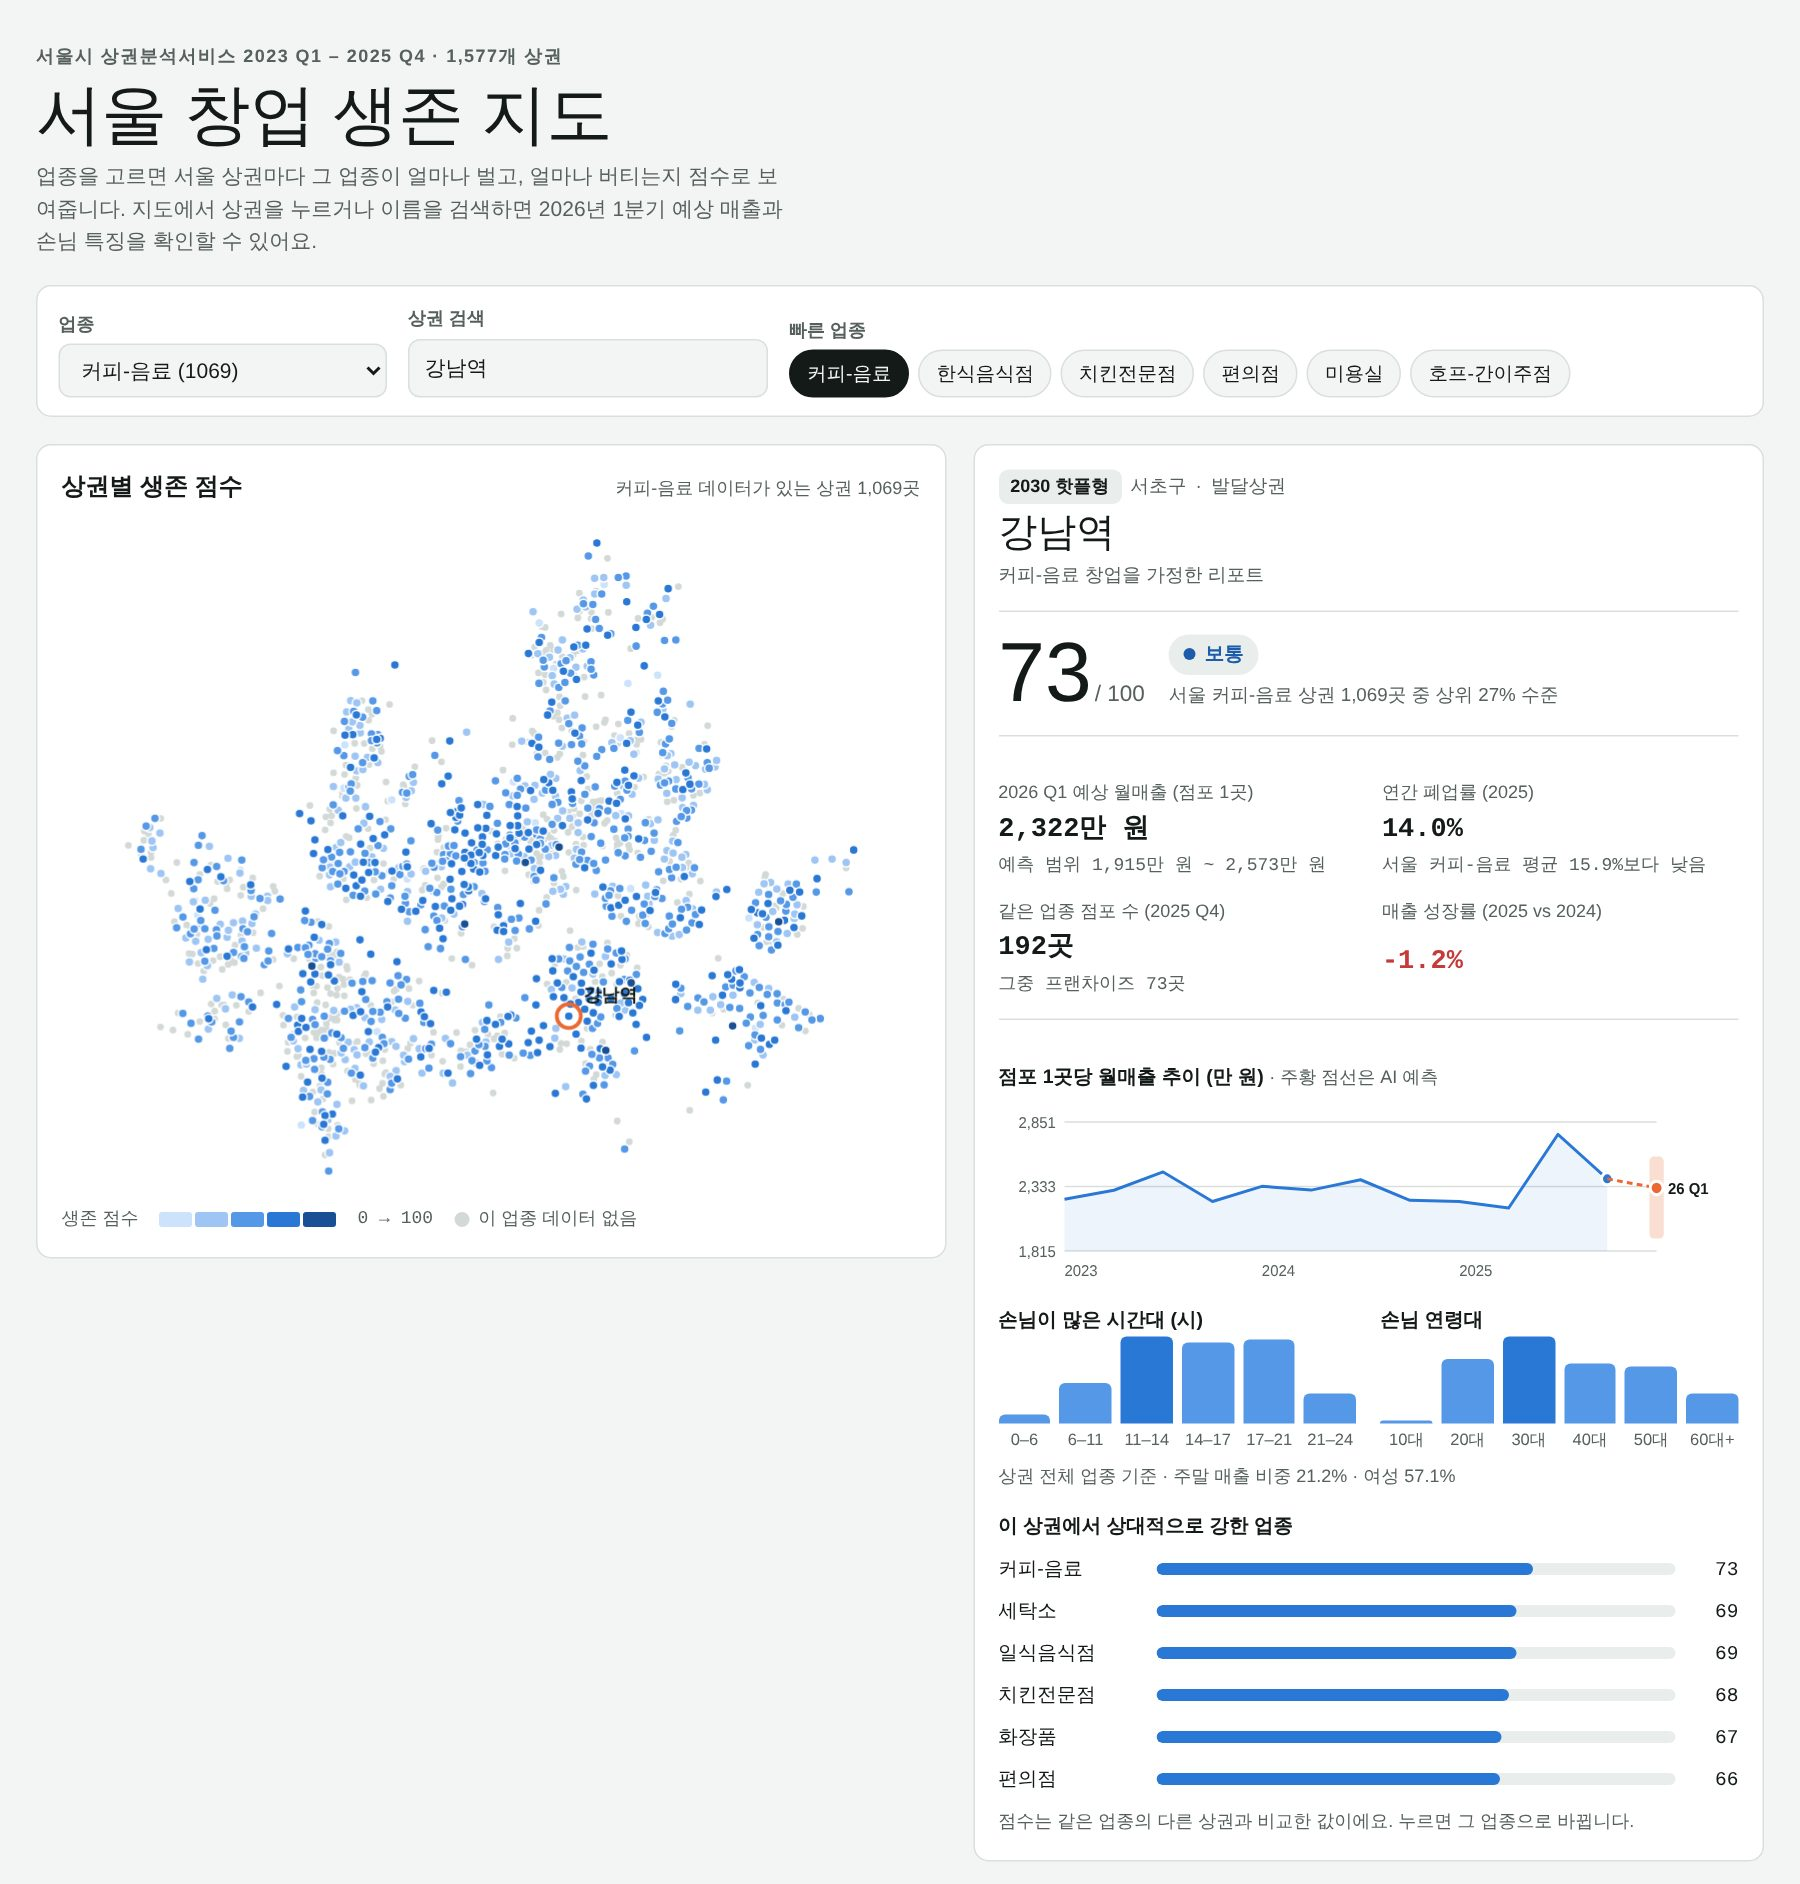

In [ ]:
# 상권 리포트 화면 (저장된 실행 결과 이미지)
from IPython.display import Image, display
try:
    display(Image('web_main.jpg'))
except (FileNotFoundError, ValueError):
    print('web_main.jpg 파일이 없으면 위 링크에서 웹서비스를 직접 확인하세요.')

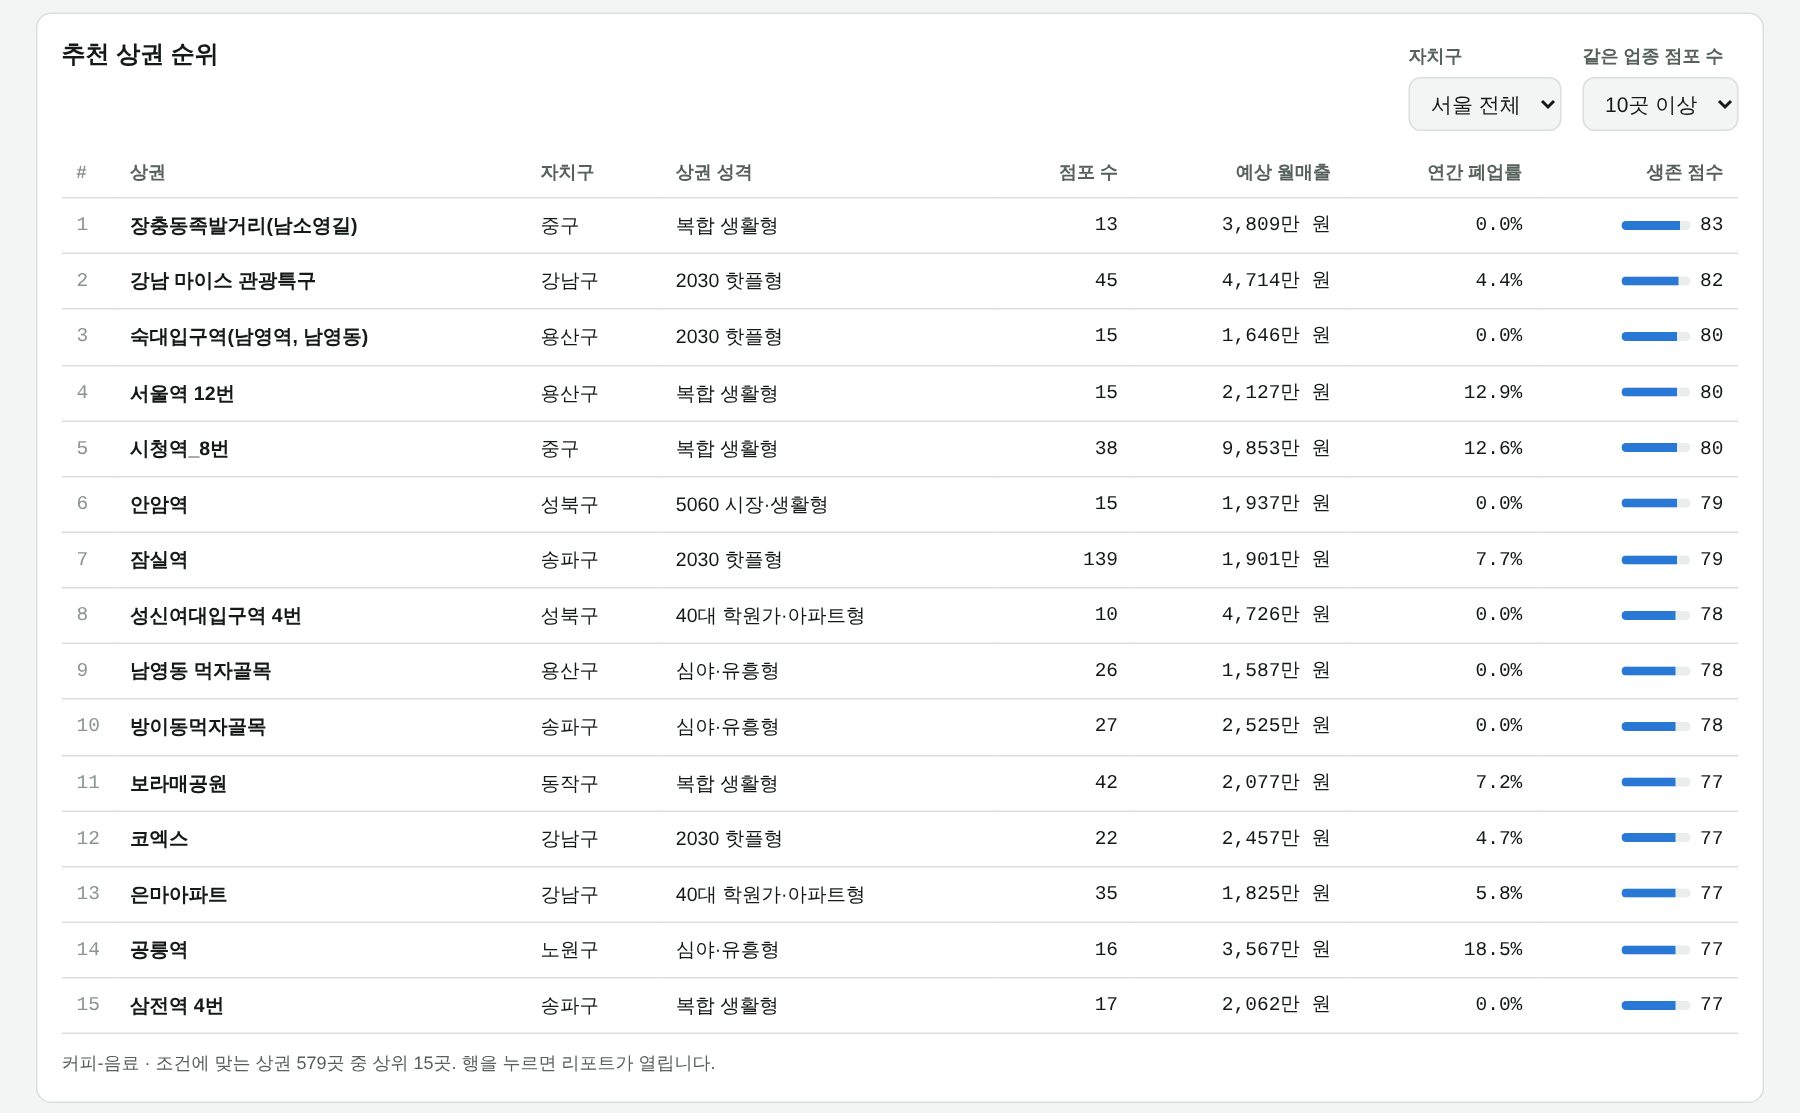

In [ ]:
# 추천 상권 순위 화면 (저장된 실행 결과 이미지)
from IPython.display import Image, display
try:
    display(Image('web_rank.jpg'))
except (FileNotFoundError, ValueError):
    print('web_rank.jpg 파일이 없으면 위 링크에서 웹서비스를 직접 확인하세요.')

### (선택) 노트북 안에서 바로 실행해 보기
`서울창업생존지도_웹.html` 파일이 이 노트북과 같은 폴더에 있으면 아래 셀을 실행해 노트북 안에서 웹서비스를 써볼 수 있습니다.

In [ ]:
from IPython.display import IFrame
IFrame('서울창업생존지도_웹.html', width='100%', height=900)